# Radar tracks, HRRR-AK grid, and DEM coverage

## Goal

Investigate where **radar observations and gridded forcing overlap**, as a first step toward designing point snow-model simulations.

1. Inspect the downloaded WY2021 HRRR-AK NetCDF and choose an example timestamp.
2. Compare the stored HRRR grid footprint, radar tracks, and six-tile DEM bounding box.
3. Check both geometric overlap and valid HRRR data at radar locations.
4. Group radar locations by stored HRRR grid cell to identify candidate areas for point modeling.

**Kernel:** JIF snow modeling (`jif_snow_modeling`).

> **Time matching is not established:** the radar CSV identifies 2021 but has no acquisition timestamp column. The editable **1 May 2021, 12:00 UTC** setting below is an illustrative snapshot, not a confirmed survey date.

> **Spatial interpretation:** this HRRR file is already reprojected to UTM at approximately 3 km spacing. We examine its stored cells without terrain downscaling. These cell IDs do not establish a one-to-one mapping to the original HRRR projection/grid.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import xarray as xr
import rioxarray
import rasterio
from rasterio.windows import Window
from rasterio.warp import transform_bounds
from pyproj import CRS, Transformer
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D
from IPython.display import display
import cartopy.crs as ccrs
import cartopy.feature as cfeature

HRRR_PATH = Path('/hdd/snow_hydrology/hrrrak/icefield_domain/netcdf/hrrrak_merged_grib_f567_WY2021_utm.nc')
RADAR_PATH = Path('/hdd/snow_hydrology/JIF_radar/ml_swe_2021.csv')
DEM_PATH = Path('/hdd/snow_hydrology/DEMs/ArcticDEM_edits/icefield_domain/jif_mosaic/jif_tiles_utm8n_20m.tif')
RADAR_EPSG = 32608  # Provisional WGS 84 / UTM 8N assumption; datum not specified in radar readme.
TARGET_TIME_UTC = pd.Timestamp('2021-05-01T12:00:00')  # Example only; update when survey dates are known.
TIME_TOLERANCE = pd.Timedelta('1h')
SAVE_OUTPUTS = True
REPO_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                  if (p / 'radar' / '02_radar_hrrrak_dem_coverage.ipynb').is_file()), None)
if REPO_ROOT is None:
    raise RuntimeError('Launch from the repository root or radar/.')
FIGURE_DIR = REPO_ROOT / 'radar' / 'figures'
DATA_DIR = REPO_ROOT / 'radar' / 'data'
if SAVE_OUTPUTS:
    FIGURE_DIR.mkdir(exist_ok=True)
    DATA_DIR.mkdir(exist_ok=True)
for path in [HRRR_PATH, RADAR_PATH, DEM_PATH]:
    if not path.is_file():
        raise FileNotFoundError(path)
print('Python:', sys.executable)
print('Radar datum assumption:', CRS.from_epsg(RADAR_EPSG).name)

Python: /home/cassie/programs/miniforge3/envs/jif_snow_modeling/bin/python
Radar datum assumption: WGS 84 / UTM zone 8N


## 1. Inspect HRRR coverage, time, and variable metadata

- Open the NetCDF lazily and load **only one timestamp of temperature and orography**.
- Read the projection from the file rather than assigning one by assumption.
- Report actual timestamp coverage, spacing, forecast steps, and any time/valid-time mismatch.
- Use per-variable units; dataset-level attributes describe one variable and are not valid metadata for every field.
- Sort the displayed snapshot coordinates west-to-east and south-to-north. Later cell indices use that sorted snapshot grid, not the original NetCDF row order.

In [2]:
with xr.open_dataset(HRRR_PATH, decode_coords='all') as ds:
    print(ds)
    grid_crs = CRS.from_user_input(ds.rio.crs)
    if not grid_crs.is_projected or grid_crs.to_epsg() != 32608:
        raise ValueError(f'Inspect this workflow before using an unexpected grid CRS: {grid_crs}')
    times = pd.DatetimeIndex(ds['time'].values)
    if not times.is_unique or not times.is_monotonic_increasing:
        raise ValueError('Time coordinate must be unique and increasing.')
    print('Grid CRS:', grid_crs.to_string())
    print('Stored time coverage:', times.min(), 'to', times.max(), '(interpreted as UTC)')
    print('Number of timestamps:', len(times))
    print('Time increments:', pd.Series(times[1:] - times[:-1]).value_counts().to_dict())
    if 'valid_time' in ds:
        if not np.array_equal(ds['valid_time'].values, ds['time'].values):
            raise ValueError('time differs from valid_time; resolve time semantics before selecting a snapshot.')
        print('time equals valid_time for every timestamp.')
    if 'step' in ds:
        print('Stored forecast lead times:', np.unique(ds['step'].values).astype('timedelta64[h]'))
    variables = pd.DataFrame([{'variable': name, 'units': v.attrs.get('units', ''),
                               'description': v.attrs.get('long_name', ''), 'dimensions': str(v.dims)}
                              for name, v in ds.data_vars.items()])
    display(variables)
    selected = times.get_indexer([TARGET_TIME_UTC], method='nearest', tolerance=TIME_TOLERANCE)[0]
    if selected < 0:
        raise ValueError('Requested time has no timestamp within TIME_TOLERANCE.')
    snapshot = ds[['temp', 'orog']].isel(time=selected).sortby('x').sortby('y').load()
    actual_time = pd.Timestamp(snapshot['time'].values)
print('Requested example time:', TARGET_TIME_UTC, 'UTC')
print('Selected stored time:', actual_time, 'UTC')
if snapshot['temp'].attrs.get('units') != 'K' or snapshot['orog'].attrs.get('units') != 'm':
    raise ValueError('Confirm temperature/orography units before plotting.')
temp_c = snapshot['temp'].values - 273.15
orography = snapshot['orog'].values
x, y = snapshot.x.values, snapshot.y.values
print('Stored grid shape (y, x):', temp_c.shape)
print('Finite temperature cells:', int(np.isfinite(temp_c).sum()), '/', temp_c.size)

<xarray.Dataset> Size: 4GB
Dimensions:       (time: 8760, y: 59, x: 31)
Coordinates:
    valid_time    (time) datetime64[ns] 70kB ...
    step          (time) timedelta64[ns] 70kB ...
  * time          (time) datetime64[ns] 70kB 2020-10-01T05:00:00 ... 2021-10-...
  * y             (y) float64 472B 6.618e+06 6.615e+06 ... 6.449e+06 6.446e+06
  * x             (x) float64 248B 4.98e+05 5.009e+05 ... 5.842e+05 5.871e+05
    spatial_ref   int32 4B ...
Data variables: (12/28)
    gust          (time, y, x) float64 128MB ...
    pressure      (time, y, x) float64 128MB ...
    orog          (time, y, x) float64 128MB ...
    temp_surface  (time, y, x) float64 128MB ...
    swe           (time, y, x) float64 128MB ...
    snowdepth     (time, y, x) float64 128MB ...
    ...            ...
    suswrf        (time, y, x) float64 128MB ...
    sulwrf        (time, y, x) float64 128MB ...
    wind          (time, y, x) float64 128MB ...
    wind_dir      (time, y, x) float64 128MB ...
    veg   

,variable,units,description,dimensions
0,gust,m s**-1,Wind speed (gust),"('time', 'y', 'x')"
1,pressure,Pa,Surface pressure,"('time', 'y', 'x')"
2,orog,m,Orography,"('time', 'y', 'x')"
3,temp_surface,K,Temperature,"('time', 'y', 'x')"
4,swe,kg m**-2,Water equivalent of accumulated snow depth (de...,"('time', 'y', 'x')"
5,snowdepth,m,Snow depth,"('time', 'y', 'x')"
6,temp,K,2 metre temperature,"('time', 'y', 'x')"
7,2sh,kg kg**-1,2 metre specific humidity,"('time', 'y', 'x')"
8,2d,K,2 metre dewpoint temperature,"('time', 'y', 'x')"
9,rh,%,2 metre relative humidity,"('time', 'y', 'x')"


## 2. Build cell edges and locate the datasets

- Derive cell boundaries from adjacent **grid centres**, including half-cell edges at the perimeter.
- Require regular spacing; do not assume the stored spacing is exactly 3,000 m.
- Transform radar coordinates and the DEM bounds into the HRRR file's CRS.
- The DEM bounding box is a coverage outline, not proof that every DEM pixel is valid. Check the DEM mask at radar locations separately.

In [3]:
def cell_edges(centres):
    centres = np.asarray(centres, dtype=float)
    diffs = np.diff(centres)
    if len(centres) < 2 or not np.all(diffs > 0) or not np.allclose(diffs, diffs[0], rtol=1e-6):
        raise ValueError('Expected a regularly spaced increasing coordinate axis.')
    return np.r_[centres[0] - diffs[0] / 2, (centres[:-1] + centres[1:]) / 2,
                 centres[-1] + diffs[-1] / 2]

x_edges, y_edges = cell_edges(x), cell_edges(y)
hrrr_bounds = (x_edges[0], y_edges[0], x_edges[-1], y_edges[-1])
print(f'Stored cell spacing: {np.diff(x)[0]:.3f} m × {np.diff(y)[0]:.3f} m')
radar = pd.read_csv(RADAR_PATH, encoding='utf-8-sig')
finite_coordinates = np.isfinite(radar[['east', 'north']]).all(axis=1)
points = radar.loc[finite_coordinates].copy()
if points.empty:
    raise ValueError('No finite radar coordinates.')
points['source_csv_row_0based'] = points.index
transform_radar = Transformer.from_crs(RADAR_EPSG, grid_crs, always_xy=True)
points['grid_x'], points['grid_y'] = transform_radar.transform(points.east.to_numpy(), points.north.to_numpy())
with rasterio.open(DEM_PATH) as dem:
    dem_bounds = transform_bounds(dem.crs, grid_crs, *dem.bounds, densify_pts=101)
    dem_native_bounds, dem_crs = dem.bounds, dem.crs
print('HRRR outer cell-edge bounds:', hrrr_bounds)
print('Six-tile DEM raster bounds:', dem_bounds)
print(f'{len(points):,} finite radar coordinates; {(~finite_coordinates).sum():,} excluded coordinate rows.')

Stored cell spacing: 2972.994 m × 2972.994 m
HRRR outer cell-edge bounds: (np.float64(496468.3178110652), np.float64(6444250.622521915), np.float64(588631.1196165059), np.float64(6619657.245312914))
Six-tile DEM raster bounds: (499900.0, 6433960.0, 595980.0, 6577740.0)
119,218 finite radar coordinates; 0 excluded coordinate rows.


## 3. Quantify overlap and match radar points to stored grid cells

### Coverage checks

- **Inside HRRR bounds:** the coordinate falls inside the outer cell edges.
- **Valid temperature/orography:** its assigned HRRR cell has finite data at the selected example time.
- **Inside DEM bounds:** the coordinate falls within the six-tile raster bounding box.
- **Valid DEM elevation:** the nearest DEM pixel is valid at that radar location.

Cell assignment uses containing cells on the regular projected grid, equivalent to nearest-centre selection except at shared boundaries. Boundary ties go east/north; outside points remain unassigned. **No interpolation or elevation correction is performed.**

In [4]:
gx, gy = points.grid_x.to_numpy(), points.grid_y.to_numpy()
col = np.searchsorted(x_edges, gx, side='right') - 1
row = np.searchsorted(y_edges, gy, side='right') - 1
inside_hrrr = (col >= 0) & (col < len(x)) & (row >= 0) & (row < len(y))
points['inside_hrrr_bounds'] = inside_hrrr
points['grid_col_west_to_east'] = pd.array(np.where(inside_hrrr, col, np.nan), dtype='Int64')
points['grid_row_south_to_north'] = pd.array(np.where(inside_hrrr, row, np.nan), dtype='Int64')
points['hrrr_temperature_C'] = np.nan
points['hrrr_orography_m'] = np.nan
points.loc[inside_hrrr, 'hrrr_temperature_C'] = temp_c[row[inside_hrrr], col[inside_hrrr]]
points.loc[inside_hrrr, 'hrrr_orography_m'] = orography[row[inside_hrrr], col[inside_hrrr]]
points['hrrr_example_time_UTC'] = str(actual_time)
points['radar_crs_assumption'] = f'EPSG:{RADAR_EPSG}'

# Blockwise sampling avoids reading the entire full-resolution DEM.
points['dem_elevation_m'] = np.nan
with rasterio.open(DEM_PATH) as dem:
    tx, ty = Transformer.from_crs(grid_crs, dem.crs, always_xy=True).transform(gx, gy)
    dr, dc = rasterio.transform.rowcol(dem.transform, tx, ty)
    dr, dc = np.asarray(dr), np.asarray(dc)
    inside_dem = (dr >= 0) & (dr < dem.height) & (dc >= 0) & (dc < dem.width)
    ids = np.flatnonzero(inside_dem)
    groups = pd.DataFrame({'id': ids, 'br': dr[ids] // 512, 'bc': dc[ids] // 512})
    values = np.full(len(points), np.nan)
    for (br, bc), group in groups.groupby(['br', 'bc']):
        r0, c0 = int(br * 512), int(bc * 512)
        window = Window(c0, r0, min(512, dem.width - c0), min(512, dem.height - r0))
        data = dem.read(1, window=window, masked=True)
        ii = group.id.to_numpy()
        values[ii] = data[dr[ii] - r0, dc[ii] - c0].astype(float).filled(np.nan)
    points['dem_elevation_m'] = values
points['inside_dem_bounds'] = inside_dem
points['valid_hrrr_temperature'] = np.isfinite(points.hrrr_temperature_C)
points['valid_hrrr_orography'] = np.isfinite(points.hrrr_orography_m)
points['valid_dem_elevation'] = np.isfinite(points.dem_elevation_m)
checks = ['inside_hrrr_bounds', 'valid_hrrr_temperature', 'valid_hrrr_orography',
          'inside_dem_bounds', 'valid_dem_elevation']
coverage_summary = pd.DataFrame([{'check': name, 'radar_points': int(points[name].sum()),
                                  'percent': 100 * points[name].mean()} for name in checks])
display(coverage_summary)
print('Flags refer to the selected HRRR snapshot and the current DEM, not all times or every meteorological variable.')
if SAVE_OUTPUTS:
    coverage_summary.to_csv(DATA_DIR / 'radar_hrrrak_dem_coverage.csv', index=False)
    points.to_csv(DATA_DIR / 'radar_hrrrak_grid_assignments.csv', index=False)

Flags refer to the selected HRRR snapshot and the current DEM, not all times or every meteorological variable.


,check,radar_points,percent
0,inside_hrrr_bounds,119218,100.0
1,valid_hrrr_temperature,119218,100.0
2,valid_hrrr_orography,119218,100.0
3,inside_dem_bounds,119218,100.0
4,valid_dem_elevation,119218,100.0


## 4. Map the overlapping extents

### Figure panels

- **Regional:** HRRR temperature cells with the downloaded DEM bounding box and all radar tracks.
- **Radar close-up:** the same field and stored grid boundaries around the radar footprint.
- **Blue outline:** outer HRRR cell edges; **orange outline:** six-tile DEM raster bounding box.
- **Magenta tracks:** radar points; grey cells have missing temperature in the selected snapshot.

The temperature field supplies spatial context at an **illustrative** 2021 timestamp. It is not a radar-date match or a snow-model validation result. Basemap features come from Natural Earth via Cartopy (cached locally or downloaded on first use).

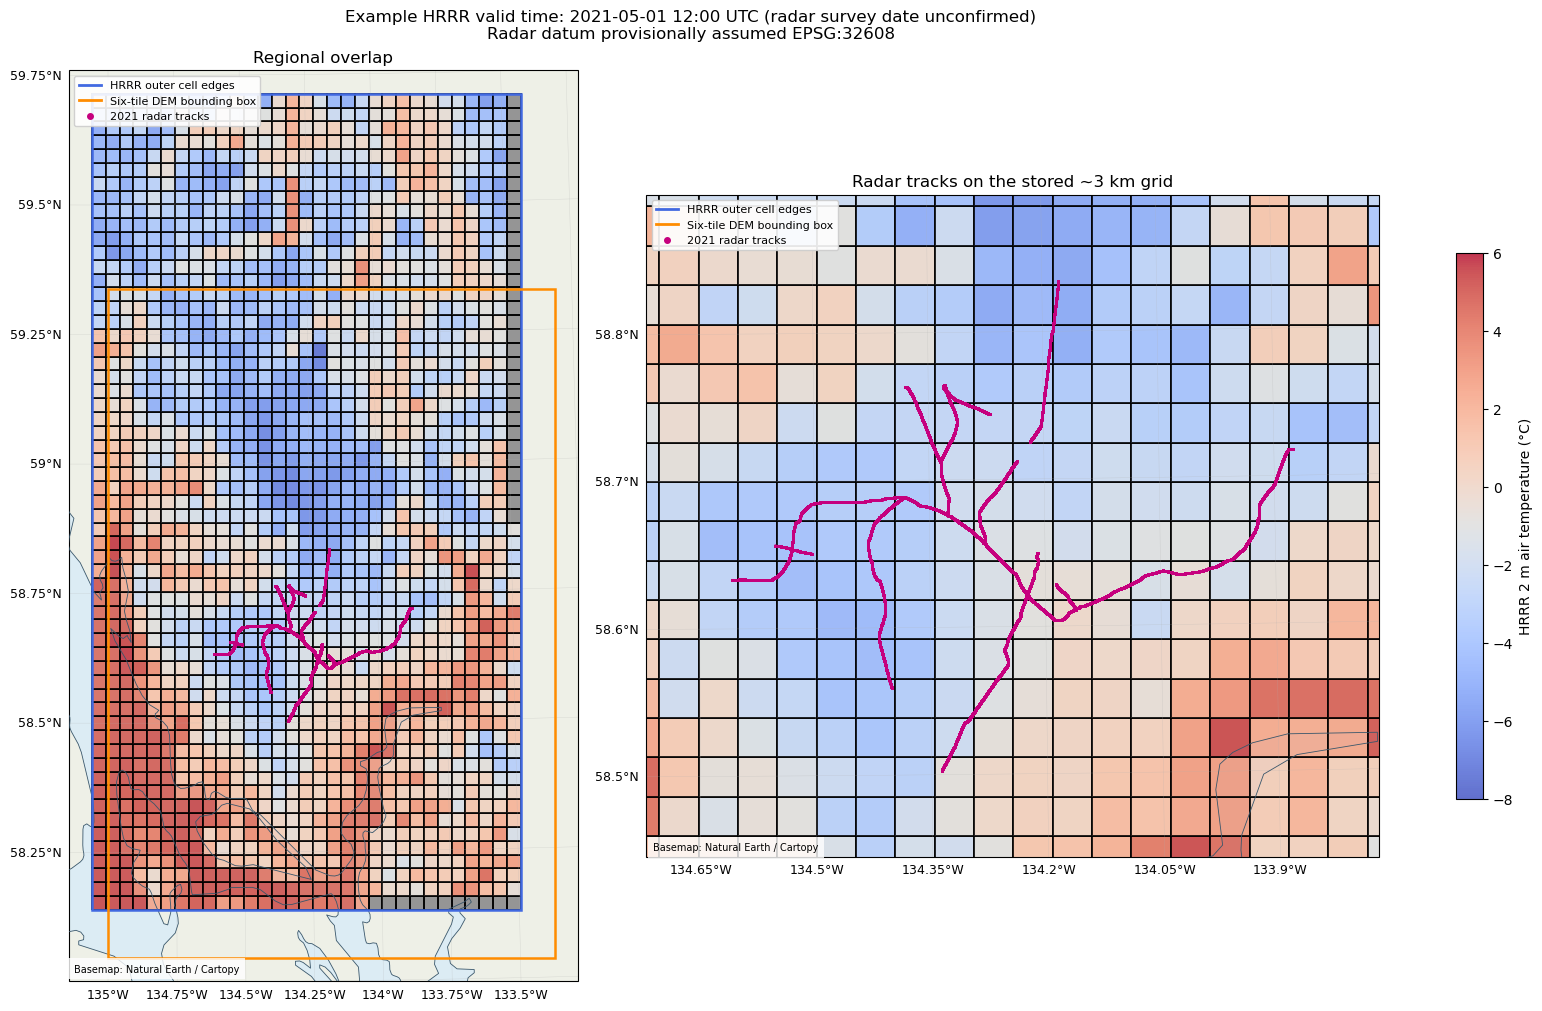

In [5]:
map_crs = ccrs.epsg(grid_crs.to_epsg())
fig, axes = plt.subplots(1, 2, figsize=(17, 10), subplot_kw={'projection': map_crs}, constrained_layout=True)
regional_bounds = (min(hrrr_bounds[0], dem_bounds[0]) - 5000,
                   min(hrrr_bounds[1], dem_bounds[1]) - 5000,
                   max(hrrr_bounds[2], dem_bounds[2]) + 5000,
                   max(hrrr_bounds[3], dem_bounds[3]) + 5000)
zoom_bounds = (gx.min() - 6500, gy.min() - 6500, gx.max() + 6500, gy.max() + 6500)
finite_temp = temp_c[np.isfinite(temp_c)]
if not finite_temp.size:
    raise ValueError('Selected snapshot has no finite temperature.')
vmin, vmax = np.floor(finite_temp.min()), np.ceil(finite_temp.max())
if vmin == vmax:
    vmax = vmin + 1
legend_handles = [Line2D([], [], color='royalblue', linewidth=2, label='HRRR outer cell edges'),
                  Line2D([], [], color='darkorange', linewidth=2, label='Six-tile DEM bounding box'),
                  Line2D([], [], color='#c6007e', marker='o', linestyle='none', markersize=4, label='2021 radar tracks')]
for ax, bounds, title in zip(axes, [regional_bounds, zoom_bounds],
                             ['Regional overlap', 'Radar tracks on the stored ~3 km grid']):
    ax.set_xlim(bounds[0], bounds[2]); ax.set_ylim(bounds[1], bounds[3])
    ax.add_feature(cfeature.OCEAN.with_scale('10m'), facecolor='#dcecf4', zorder=0)
    ax.add_feature(cfeature.LAND.with_scale('10m'), facecolor='#eef0e7', zorder=0)
    ax.pcolormesh(x_edges, y_edges, np.where(np.isfinite(temp_c), np.nan, 1),
                   transform=map_crs, cmap='Greys', vmin=0, vmax=2, shading='flat', zorder=1)
    mesh = ax.pcolormesh(x_edges, y_edges, np.ma.masked_invalid(temp_c), transform=map_crs,
                         cmap='coolwarm', vmin=vmin, vmax=vmax, shading='flat', alpha=0.8,
                         edgecolors=(0, 0, 0, 0.22), linewidth=0.2, zorder=2)
    ax.coastlines(resolution='10m', color='#38566b', linewidth=0.6, zorder=3)
    for rectangle, colour in [(hrrr_bounds, 'royalblue'), (dem_bounds, 'darkorange')]:
        left, bottom, right, top = rectangle
        ax.add_patch(Rectangle((left, bottom), right - left, top - bottom, fill=False,
                                edgecolor=colour, linewidth=1.8, transform=map_crs, zorder=4))
    ax.scatter(gx, gy, transform=map_crs, s=0.6, color='#c6007e', rasterized=True, zorder=5)
    grid = ax.gridlines(draw_labels=True, linewidth=0.3, alpha=0.4)
    grid.top_labels = False; grid.right_labels = False
    grid.xlabel_style = {'size': 9}; grid.ylabel_style = {'size': 9}
    ax.set_title(title)
    ax.legend(handles=legend_handles, loc='upper left', fontsize=8, framealpha=0.9)
    ax.text(0.01, 0.01, 'Basemap: Natural Earth / Cartopy', transform=ax.transAxes,
             fontsize=7, zorder=6, bbox={'facecolor': 'white', 'alpha': 0.8, 'edgecolor': 'none'})
fig.colorbar(mesh, ax=list(axes), shrink=0.6, label='HRRR 2 m air temperature (°C)')
fig.suptitle(f'Example HRRR valid time: {actual_time:%Y-%m-%d %H:%M} UTC (radar survey date unconfirmed)\n'
             f'Radar datum provisionally assumed EPSG:{RADAR_EPSG}', fontsize=12)
if SAVE_OUTPUTS:
    fig.savefig(FIGURE_DIR / 'radar_hrrrak_dem_coverage_2021.png', dpi=180, bbox_inches='tight')
plt.show()

## 5. Candidate grid cells for point-model design

- Summarize **each stored UTM grid cell intersected by radar points**, with row counts, profiles, and DEM elevation ranges.
- Report the distance from each radar point to its assigned cell centre.
- Compare median radar-location DEM elevation with HRRR orography to identify scale differences; this is **not an automatic lapse-rate correction**.
- A cell intersected by tracks is a candidate grouping, not necessarily a single representative modeling site. Elevation, glacier setting, and survey timing still matter.
- Keep duplicates and repeated locations visible: counts are source rows, not independent observations or sampled area.

55 stored grid cells intersect the radar tracks.


,grid_row_south_to_north,grid_col_west_to_east,radar_rows,profiles,cell_centre_x,cell_centre_y,dem_elevation_min_m,dem_elevation_median_m,dem_elevation_max_m,hrrr_orography_m,example_temperature_C,max_distance_to_cell_centre_m,median_dem_minus_hrrr_orography_m,example_time_UTC
17,18,16,5275,2,545522.712320,6.499251e+06,1069.372803,1094.975342,1120.766602,1055.800987,-0.779028,1604.080633,39.174355,2021-05-01 12:00:00
24,19,10,4999,2,527684.750681,6.502224e+06,1507.284912,1546.673706,1567.579102,1589.769737,-4.091528,1612.854325,-43.096031,2021-05-01 12:00:00
36,20,15,4621,1,542549.718714,6.505197e+06,1232.911377,1295.382935,1324.349487,1246.113487,-1.779028,1828.587791,49.269448,2021-05-01 12:00:00
33,20,12,4306,2,533630.737894,6.505197e+06,1348.362427,1372.398682,1420.223511,1382.800987,-3.404028,1519.360581,-10.402305,2021-05-01 12:00:00
9,17,16,4057,2,545522.712320,6.496278e+06,1017.534912,1049.957031,1082.583374,1017.707237,-0.904028,1639.008476,32.249794,2021-05-01 12:00:00
27,19,15,4004,2,542549.718714,6.502224e+06,1144.764526,1205.412964,1232.911377,1156.207237,-1.404028,1827.783210,49.205727,2021-05-01 12:00:00
10,17,17,3720,2,548495.705927,6.496278e+06,977.538147,983.510864,1017.534912,939.957237,-0.091528,1971.639612,43.553627,2021-05-01 12:00:00
1,14,14,3606,1,539576.725107,6.487359e+06,1216.822266,1245.794067,1265.578247,1253.488487,-2.154028,1895.749969,-7.694419,2021-05-01 12:00:00
6,16,15,3546,1,542549.718714,6.493305e+06,1067.165405,1100.753418,1138.206421,1107.332237,-1.404028,1837.889962,-6.578819,2021-05-01 12:00:00
35,20,14,3492,2,539576.725107,6.505197e+06,1248.098633,1271.007629,1302.358398,1238.957237,-2.029028,1709.965659,32.050393,2021-05-01 12:00:00


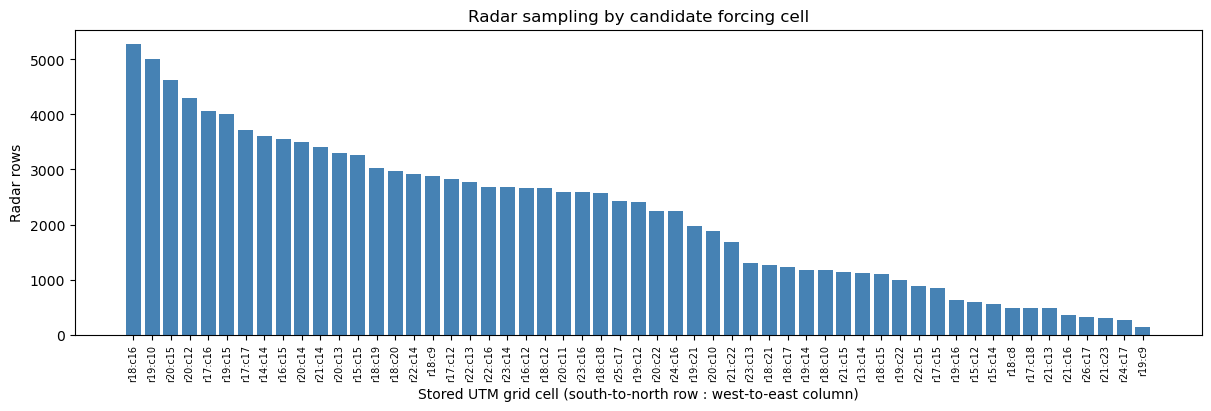

In [6]:
assigned = points.loc[inside_hrrr].copy()
if assigned.empty:
    raise ValueError('No radar points overlap the HRRR grid.')
cc = assigned.grid_col_west_to_east.to_numpy(dtype=int)
rr = assigned.grid_row_south_to_north.to_numpy(dtype=int)
assigned['cell_centre_x'] = x[cc]
assigned['cell_centre_y'] = y[rr]
assigned['distance_to_cell_centre_m'] = np.hypot(assigned.grid_x - x[cc], assigned.grid_y - y[rr])
candidates = assigned.groupby(['grid_row_south_to_north', 'grid_col_west_to_east']).agg(
    radar_rows=('profile', 'size'), profiles=('profile', 'nunique'),
    cell_centre_x=('cell_centre_x', 'first'), cell_centre_y=('cell_centre_y', 'first'),
    dem_elevation_min_m=('dem_elevation_m', 'min'), dem_elevation_median_m=('dem_elevation_m', 'median'),
    dem_elevation_max_m=('dem_elevation_m', 'max'), hrrr_orography_m=('hrrr_orography_m', 'first'),
    example_temperature_C=('hrrr_temperature_C', 'first'),
    max_distance_to_cell_centre_m=('distance_to_cell_centre_m', 'max')).reset_index()
candidates['median_dem_minus_hrrr_orography_m'] = candidates.dem_elevation_median_m - candidates.hrrr_orography_m
candidates['example_time_UTC'] = str(actual_time)
candidates = candidates.sort_values('radar_rows', ascending=False)
assert candidates.radar_rows.sum() == int(inside_hrrr.sum())
print(f'{len(candidates):,} stored grid cells intersect the radar tracks.')
display(candidates)
if SAVE_OUTPUTS:
    candidates.to_csv(DATA_DIR / 'radar_hrrrak_candidate_cells.csv', index=False)

fig, ax = plt.subplots(figsize=(12, 4), constrained_layout=True)
labels = [f'r{r}:c{c}' for r, c in candidates[['grid_row_south_to_north', 'grid_col_west_to_east']].itertuples(index=False, name=None)]
ax.bar(np.arange(len(candidates)), candidates.radar_rows, color='steelblue')
ax.set_xticks(np.arange(len(candidates)), labels, rotation=90, fontsize=7)
ax.set(xlabel='Stored UTM grid cell (south-to-north row : west-to-east column)',
       ylabel='Radar rows', title='Radar sampling by candidate forcing cell')
if SAVE_OUTPUTS:
    fig.savefig(FIGURE_DIR / 'radar_hrrrak_candidate_cell_counts.png', dpi=180)
plt.show()

## Next steps toward point modeling

- [ ] **Confirm survey dates:** replace the illustrative timestamp with actual radar acquisition dates or time windows.
- [ ] **Confirm radar datum:** verify alignment before selecting precise point locations.
- [ ] **Choose representative sites:** account for within-cell elevation range, profiles, and glacier setting rather than using a grid centre automatically.
- [ ] **Trace the original HRRR grid:** determine how projected cells relate to native forcing locations before extracting new model input series.
- [ ] **Check full forcing availability:** this notebook checks temperature and orography at one time; audit all required variables over the simulation period next.
- [ ] **Choose terrain adjustments:** evaluate elevation and meteorological corrections explicitly if terrain downscaling is needed.
- [ ] **Plan model validation:** match observation timing and model snow variables before computing errors. HRRR snow fields, point-model outputs, and radar SWE are distinct datasets.

**Outputs:** maps in `radar/figures/`; overlap tables and candidate-cell assignments in `radar/data/`. Both are ignored by Git. The executed notebook embeds the figures and summaries. Original datasets are unchanged.